# Word Embeddings from Scratch

A walkthrough of every step that turns raw text into word vectors — no gensim, no
pretrained embeddings, no `Word2Vec` import.

```
raw text  ->  tokens  ->  vocabulary  ->  ids  ->  (center, context) pairs
          ->  negatives  ->  skip-gram model  ->  vectors  ->  3D map
```

Every section does three things: it explains the idea, runs the code, and prints
evidence. Everything it needs is defined in the notebook itself — it imports
nothing from the project, so it runs on its own.

Ten sections: the corpus, tokenisation, vocabulary, pairs, negatives, the model, the training
loop, nearest neighbours, and a 3D map. Every claim in the text is printed by the cell above it.

In [33]:
import os
import sys
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# torch prints a sparse-tensor invariant notice on every optimiser step; it is
# not a problem and it drowns the output we actually care about.
warnings.filterwarnings("ignore", message="Sparse invariant checks")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(os.cpu_count() or 1)

print("python :", sys.version.split()[0])
print("numpy  :", np.__version__)
print("torch  :", torch.__version__)
print("device :", DEVICE)

python : 3.13.16
numpy  : 2.1.3
torch  : 2.11.0+cu130
device : cuda


## 1. The corpus

[`roneneldan/TinyStories`](https://huggingface.co/datasets/roneneldan/TinyStories) — short
children's stories. Simple grammar, narrative structure, and a small vocabulary, which is
exactly what we want: the model can learn meaningful vectors in minutes on a CPU.

`prepare_corpus.py` streamed stories until it collected 20M tokens and wrote them to
`data/tinystories_20m.txt` (99 MB). The file is git-ignored; the script reproduces it.

In [34]:
def load_corpus(path: Path) -> str:
    """Read the corpus as one lowercased string."""
    text = path.read_text(encoding="utf-8")
    if not text.strip():
        raise ValueError(f"corpus is empty: {path}")
    return text.lower()


def find_corpus() -> Path:
    """The corpus next to the notebook, or wherever Kaggle mounted it."""
    for candidate in (Path("data/tinystories_20m.txt"), Path("tinystories_20m.txt")):
        if candidate.is_file():
            return candidate
    if Path("/kaggle/input").exists():
        hits = sorted(Path("/kaggle/input").rglob("tinystories_20m.txt"))
        if hits:
            return hits[0]
    raise FileNotFoundError(
        "tinystories_20m.txt not found: run prepare_corpus.py, or attach the Kaggle dataset"
    )


corpus_path = find_corpus()
text = load_corpus(corpus_path)

print(f"file size  : {corpus_path.stat().st_size / 1e6:.0f} MB")
print(f"characters : {len(text):,}")
print()
print(text[:300])

file size  : 103 MB
characters : 102,798,741

one day, a little girl named lily found a needle in her room. she knew it was difficult to play with it because it was sharp. lily wanted to share the needle with her mom, so she could sew a button on her shirt.  lily went to her mom and said, "mom, i found this needle. can you share it with me and 


`load_corpus` lowercases everything. `The` and `the` must be the same word — otherwise the
vocabulary is split in two and every count is halved.

## 2. Tokenization — what survives and what is dropped

The rule is one regex: `[a-z]+` plus an optional internal apostrophe (so `don't` stays one
token). Everything else — digits, punctuation, emoji, non-Latin script — is dropped.

"Maybe" says the distributional hypothesis — but only words carry meaning here. `!` and `2011`
do not. Keeping them would add thousands of meaningless columns to every count table later.

In [35]:
import re

# ASCII letters only, with an optional internal apostrophe ("don't").
# Numbers, punctuation and non-English words are dropped on purpose.
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")


def tokenize(text: str) -> list[str]:
    """Split text into word tokens."""
    return TOKEN_RE.findall(text)


demo = "The King's castle was huge — he lived there in 2011!"
rows = []
for word in demo.lower().split():
    produced = tokenize(word)
    if not produced:
        note = "dropped"
    elif produced == [word]:
        note = "kept"
    else:
        note = "rewritten"
    rows.append({"raw": word, "tokens": produced, "note": note})

pd.DataFrame(rows)

,raw,tokens,note
0,the,[the],kept
1,king's,[king's],kept
2,castle,[castle],kept
3,was,[was],kept
4,huge,[huge],kept
5,—,[],dropped
6,he,[he],kept
7,lived,[lived],kept
8,there,[there],kept
9,in,[in],kept


In [36]:
tokens = tokenize(text)

print(f"tokens       : {len(tokens):,}")
print(f"unique forms : {len(set(tokens)):,}")
print()
print("first 40 tokens:")
print(" ".join(tokens[:40]))

tokens       : 20,104,405
unique forms : 19,354

first 40 tokens:
one day a little girl named lily found a needle in her room she knew it was difficult to play with it because it was sharp lily wanted to share the needle with her mom so she could sew a


19,354 unique forms for 20M tokens. The vocabulary is small, but the tail is long — and the
tail is what hurts: every unique form becomes a row and a column in every table we build.

## 3. Vocabulary — keep the head, bucket the tail

Zipf's law: a handful of words carry most of the text, and a long tail of words appears once
or twice. If we keep every form, the model spends most of its parameters on words it will
never see enough times to learn.

So: words with at least 5 occurrences get their own id; everything else shares id `0`
(`<unk>`). The table below shows what that costs and what it saves.

In [37]:
def build_vocab(tokens: list[str], min_count: int = 5) -> dict[str, int]:
    """Map frequent words to consecutive ids. Id 0 is always <unk>."""
    counts = Counter(tokens)
    kept = [pair for pair in counts.items() if pair[1] >= min_count]
    kept.sort(key=lambda pair: (-pair[1], pair[0]))   # reproducible ids
    vocab = {"<unk>": 0}
    for word, _ in kept:
        vocab[word] = len(vocab)
    return vocab


def encode(tokens: list[str], vocab: dict[str, int]) -> np.ndarray:
    """Replace tokens with ids; rare and unseen words become <unk> (id 0).

    np.fromiter writes straight into the array: 4 bytes per token instead of a
    pointer per token.
    """
    return np.fromiter((vocab.get(token, 0) for token in tokens),
                       dtype=np.int32, count=len(tokens))


counts = Counter(tokens)
vocab = build_vocab(tokens)
ids = encode(tokens, vocab)
words = list(vocab)  # index i holds the word whose id is i

unk_rate = (ids == 0).mean()
print(f"unique forms : {len(counts):,}")
print(f"vocab (>= 5) : {len(vocab):,}")
print(f"UNK rate     : {unk_rate:.2%} of all tokens")
print()

top = pd.DataFrame(counts.most_common(15), columns=["word", "count"])
top["share %"] = (100 * top["count"] / len(tokens)).round(2)
top["cumulative %"] = top["share %"].cumsum().round(2)
top

unique forms : 19,354
vocab (>= 5) : 11,381
UNK rate     : 0.07% of all tokens



,word,count,share %,cumulative %
0,the,1101233,5.48,5.48
1,and,976573,4.86,10.34
2,to,684285,3.40,13.74
3,a,622057,3.09,16.83
4,was,519382,2.58,19.41
5,he,437355,2.18,21.59
6,she,419700,2.09,23.68
7,it,366089,1.82,25.50
8,they,361820,1.80,27.30
9,her,268610,1.34,28.64


## 4. Encoding — words become ids

From here on, words are integers. The mapping is arbitrary but deterministic: frequent words
first, ties broken alphabetically, so a rerun produces the exact same ids.

In [38]:
start = 5000
window = tokens[start:start + 12]

pd.DataFrame({
    "position": range(start, start + 12),
    "word": window,
    "id": ids[start:start + 12],
    "decoded": [words[i] for i in ids[start:start + 12]],
})

,position,word,id,decoded
0,5000,friends,57,friends
1,5001,did,84,did
2,5002,not,36,not
3,5003,laugh,530,laugh
4,5004,at,49,at
5,5005,him,44,him
6,5006,they,9,they
7,5007,ran,90,ran
8,5008,to,3,to
9,5009,help,80,help


`decoded` equals `word` because the vocabulary is a bijection. The interesting row is the one
where a rare word appears: it shows `0`, and `0` decodes to `<unk>` — information that was
lost, not information that was invented.

## 5. Context windows — the training signal

The only supervision we have is *which words appear near which words*. Pick a center word and
look `window` positions left and right. Those neighbours are the labels the model will learn
to predict.

The window is symmetric: `up` is a context of `get`, and `get` is a context of `up`. It is also
randomised during training — each sampled pair gets its own distance (1..5) and direction — so
the model does not overfit to exact positions.

In [39]:
center = 5012

pd.DataFrame(
    {
        "distance": list(range(-3, 4)),
        "word": [tokens[center + o] for o in range(-3, 4)],
        "id": [int(ids[center + o]) for o in range(-3, 4)],
        "role": ["context"] * 3 + ["CENTER"] + ["context"] * 3,
    }
)

,distance,word,id,role
0,-3,help,80,context
1,-2,zigzag,3295,context
2,-1,get,124,context
3,0,up,47,CENTER
4,1,zigzag's,0,context
5,2,friends,57,context
6,3,told,165,context


In [40]:
def window_pairs(ids, position: int, window: int = 5) -> list[int]:
    """The context ids around one position, inside the window."""
    start = max(position - window, 0)
    end = min(position + window + 1, len(ids))
    return [int(ids[i]) for i in range(start, end) if i != position]


print("sentence:")
print(" ".join(tokens[center - 8:center + 9]))
print()

neighbours = window_pairs(ids, center, window=3)
print("window_pairs ->", [words[i] for i in neighbours])
print()
print(f"20M tokens x 10 neighbours = {20_000_000 * 10:,} pairs per pass over the corpus")

sentence:
at him they ran to help zigzag get up zigzag's friends told him not to be embarrassed

window_pairs -> ['help', 'zigzag', 'get', '<unk>', 'friends', 'told']

20M tokens x 10 neighbours = 200,000,000 pairs per pass over the corpus


200 million pairs per pass. Materialising them costs ~1.6 GB and buys nothing — every epoch
can draw a fresh sample. `sample_pairs` therefore draws pairs on demand: random position,
random distance, random direction.

In [41]:
def sample_pairs(ids, batch_size: int, window: int = 5, rng=None):
    """Draw (center, context) pairs instead of materialising all of them.

    20M tokens x 10 neighbours is 200M pairs; sampling keeps memory flat.
    Pairs touching <unk> (id 0) are rejected and redrawn: it is a bucket, not a word.
    """
    rng = rng or np.random.default_rng()
    centers = np.empty(batch_size, dtype=np.int32)
    contexts = np.empty(batch_size, dtype=np.int32)

    filled = 0
    while filled < batch_size:
        missing = batch_size - filled
        positions = rng.integers(window, len(ids) - window, size=missing)
        steps = rng.integers(1, window + 1, size=missing) * rng.choice([-1, 1], size=missing)
        context_positions = positions + steps
        keep = (ids[positions] != 0) & (ids[context_positions] != 0)
        taken = int(keep.sum())
        centers[filled:filled + taken] = ids[positions[keep]]
        contexts[filled:filled + taken] = ids[context_positions[keep]]
        filled += taken

    return centers, contexts


rng = np.random.default_rng(0)
centers, contexts = sample_pairs(ids, 8, window=5, rng=rng)

pd.DataFrame({
    "center": [words[i] for i in centers],
    "context (positive)": [words[i] for i in contexts],
})

,center,context (positive)
0,in,the
1,the,even
2,a,bird
3,the,explore
4,she,was
5,mom,did
6,nodded,nice
7,away,grab


Every row is a real co-occurrence: `even` really does appear within five tokens of `the`
somewhere in the corpus. The pairs look "loose" because the sampler draws a random distance
(1..5) and a random direction for each pair, instead of always taking the immediate neighbour.
That is deliberate: it stops the model from memorising word positions and forces it to learn
something about meaning instead.

## 6. Negative sampling

A positive pair says "these two words belong together". On its own that is a weak signal: the
model could score every pair high and never learn. So each positive is paired with a few
random words that should score *low*.

Why only a few? Updating against all 11,381 words per example is expensive and pointless —
most of them are irrelevant. Five negatives capture most of the gradient at 1/2000 of the cost.

Why sampled by `count ** 0.75` and not by raw frequency? Because raw frequency makes the
distribution extremely sharp: `the` alone is 5.5% of all tokens, and rare words would almost
never appear as negatives. The 0.75 exponent flattens the head while keeping the ordering.

In [42]:
def negative_distribution(ids, vocab_size: int, power: float = 0.75) -> np.ndarray:
    """Unigram counts raised to `power`, normalised.

    power=1.0 samples exactly by frequency; 0.75 flattens the head so common
    words still dominate but rare words are not ignored.
    """
    counts = np.bincount(ids, minlength=vocab_size).astype(np.float64)
    weights = counts**power
    weights[0] = 0.0   # <unk> is a bucket, not a word: never draw it
    return weights / weights.sum()


p_unigram = negative_distribution(ids, len(vocab), power=1.0)
p_word2vec = negative_distribution(ids, len(vocab), power=0.75)

show = ["the", "and", "cat", "king", "mountain", "castle"]
pd.DataFrame({
    "word": show,
    "count": [counts[w] for w in show],
    "P (raw frequency)": [p_unigram[vocab[w]] for w in show],
    "P (power 0.75)": [p_word2vec[vocab[w]] for w in show],
})

,word,count,P (raw frequency),P (power 0.75)
0,the,1101233,0.054815,0.020935
1,and,976573,0.048610,0.019131
2,cat,13692,0.000682,0.000779
3,king,2122,0.000106,0.000193
4,mountain,1448,0.000072,0.000145
5,castle,4573,0.000228,0.000342


In [43]:
def sample_negatives(batch_size, num_negatives, probabilities, rng):
    """Draw random word ids to act as negative examples."""
    cumulative = np.cumsum(probabilities)
    cumulative /= cumulative[-1]   # guard against float drift below 1.0
    cumulative[-1] = 1.0
    draws = rng.random((batch_size, num_negatives))
    return np.searchsorted(cumulative, draws).astype(np.int32)


centers, contexts = sample_pairs(ids, 1, window=5, rng=rng)
negatives = sample_negatives(1, 5, p_word2vec, rng)

rows = [{"word": words[centers[0]], "role": "CENTER", "target": 1}]
rows.append({"word": words[contexts[0]], "role": "positive context", "target": 1})
for negative in negatives[0]:
    rows.append({"word": words[negative], "role": "negative", "target": 0})

print("training example: one positive pair and five negatives")
pd.DataFrame(rows)

training example: one positive pair and five negatives


,word,role,target
0,pigeon,CENTER,1
1,old,positive context,1
2,rolled,negative,0
3,day,negative,0
4,lid,negative,0
5,important,negative,0
6,named,negative,0


`target = 1` means "push the score up", `target = 0` means "push the score down". That is the
entire learning signal — there is no labelled dataset of semantic relations anywhere.

## 7. The model — two tables and a dot product

This is the whole network: two lookup tables and a dot product. No hidden layer, no bias, no
activation. The embedding **is** the hidden layer, and the weights of the first table are the
artifact we keep.

| piece | shape | what it holds |
|---|---|---|
| `center` table | 11,381 x 100 | a word as the focus |
| `context` table | 11,381 x 100 | the same word as a neighbour |
| input | (B,) | center ids |
| labels | (B, K+1) | 1 for the real neighbour, 0 for the negatives |
| output | (B, K+1) | one raw score per pair |

Two tables, not one: a word plays two different roles, and sharing a single vector for both
mixes the two gradients. Word2Vec does the same. At the end we keep the `center` table.

In [44]:
import torch
import torch.nn.functional as F

class SkipGram(torch.nn.Module):
    """Two embedding tables and a dot product. Nothing else.

    center  : what a word looks like when it is the focus.
    context : what a word looks like when it sits in the neighbourhood.
    """

    def __init__(self, vocab_size: int, dim: int = 100, sparse: bool = True) -> None:
        super().__init__()
        # sparse keeps each step's gradient on the rows that were used, which is
        # what makes a CPU viable. CUDA has no sparse Adagrad kernel, so the GPU
        # path asks for dense tables instead.
        self.center = torch.nn.Embedding(vocab_size, dim, sparse=sparse)
        self.context = torch.nn.Embedding(vocab_size, dim, sparse=sparse)

        # PyTorch's default N(0, 1) makes dot products ~sqrt(d) and saturates the
        # sigmoid, so every gradient dies. Word2Vec uses a small uniform box.
        bound = 0.5 / dim
        torch.nn.init.uniform_(self.center.weight, -bound, bound)
        torch.nn.init.uniform_(self.context.weight, -bound, bound)

    def forward(self, centers, contexts):
        """centers: (B,)   contexts: (B, K)   ->   scores: (B, K)"""
        return torch.einsum("bd,bkd->bk", self.center(centers), self.context(contexts))


torch.manual_seed(0)   # fixed init: the "before training" numbers must be reproducible
DIM = 200   # embedding size

model = SkipGram(vocab_size=len(vocab), dim=DIM, sparse=DEVICE.type == "cpu").to(DEVICE)
print("center table :", tuple(model.center.weight.shape))
print("context table:", tuple(model.context.weight.shape))
print("parameters   :", f"{sum(p.numel() for p in model.parameters()):,}")

center table : (11381, 200)
context table: (11381, 200)
parameters   : 4,552,400


### Initialisation is a design decision, not a detail

PyTorch fills `nn.Embedding` with `N(0, 1)`. With 200 dimensions the dot product of two such
vectors has a standard deviation around 10, so every score starts at roughly +-10, `sigmoid`
saturates, and the gradients are dead on arrival.

We override it with the Word2Vec box, `U(-0.5/d, 0.5/d)`. Scores start at zero, `sigmoid` at
0.5, and the loss at exactly `ln 2 = 0.693` — the value of maximal ignorance.

In [45]:
rng = np.random.default_rng(0)
centers, contexts = sample_pairs(ids, 4096, window=5, rng=rng)

with torch.no_grad():
    logits = model(
        torch.as_tensor(centers, dtype=torch.long, device=DEVICE),
        torch.as_tensor(contexts, dtype=torch.long, device=DEVICE).unsqueeze(1),
    )
    loss = F.binary_cross_entropy_with_logits(logits, torch.ones_like(logits))

print(f"UNK inside batch : {(centers == 0).sum() + (contexts == 0).sum()}")
print(f"logits           : mean={logits.mean():+.6f}  std={logits.std():.6f}")
print(f"sigmoid(logit)   : {torch.sigmoid(logits).mean():.4f}")
print(f"loss (positives) : {loss:.4f}   (ln 2 = {np.log(2):.4f})")

UNK inside batch : 0
logits           : mean=-0.000000  std=0.000030
sigmoid(logit)   : 0.5000
loss (positives) : 0.6931   (ln 2 = 0.6931)


The model is a random number generator with a vocabulary: every score is zero, every sigmoid is
0.5, and the loss is exactly `ln 2`. Section 8 trains it.

## 8. Training: score, loss, step

Five lines, and they never change:

| line | what it does |
|---|---|
| sample a batch of real `(center, context)` pairs | what the corpus says |
| sample `K` random words per pair | what the corpus does *not* say |
| `logits = model(centers, contexts)` | one dot product per pair |
| `loss = BCEWithLogits(logits, targets)` | push positives up, negatives down |
| `backward()` + `step()` | nudge the 2.3M numbers downhill |

`targets` is `1` in column 0 and `0` in columns 1..K. That is the entire supervision signal:
no labels, no human annotation, no dictionary. The corpus is the teacher.

This is the real run, not a demo: 54,931 steps × 8,192 pairs = 450M pairs. A 200-dimensional
table needs more updates than a 100-dimensional one to fill, and nine passes is what fits in a
ten-minute budget. On a GPU that is about ten minutes; on four CPU cores, about an hour. The
notebook picks whichever device it finds. Everything after this point uses the model trained here,
and the vectors are saved to `outputs/` at the end.

In [53]:
import time

from torch import nn

BATCH, K, WINDOW = 8192, 5, 2
STEPS = 9 * 50_000_000 // BATCH   # 450M pairs, nine passes of 50M


def neighbours(weight, word, k=4):
    """Closest words by cosine similarity, with the word itself removed."""
    E = weight.detach().cpu().numpy()
    unit = E / np.linalg.norm(E, axis=1, keepdims=True)
    scores = unit @ unit[vocab[word]]
    best = np.argsort(-scores)[: k + 1]
    return [f"{words[i]}={scores[i]:.2f}" for i in best if i != vocab[word]][:k]


rng = np.random.default_rng(0)
torch.manual_seed(0)
model = SkipGram(vocab_size=len(vocab), dim=DIM, sparse=DEVICE.type == "cpu").to(DEVICE)
optimizer = torch.optim.Adagrad(model.parameters(), lr=0.1)
loss_fn = nn.BCEWithLogitsLoss()

before_neighbours = {w: neighbours(model.center.weight, w) for w in ("king", "dog")}

probabilities = negative_distribution(ids, len(vocab))
targets = torch.cat([torch.ones(BATCH, 1), torch.zeros(BATCH, K)], dim=1).to(DEVICE)

history = []
started = time.perf_counter()
for step in range(1, STEPS + 1):
    centers, contexts = sample_pairs(ids, BATCH, window=WINDOW, rng=rng)
    negatives = sample_negatives(BATCH, K, probabilities, rng)
    logits = model(
        torch.as_tensor(centers, dtype=torch.long, device=DEVICE),
        torch.as_tensor(np.column_stack([contexts, negatives]), dtype=torch.long, device=DEVICE),
    )
    loss = loss_fn(logits, targets)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    history.append((step, float(loss.detach())))
    if step % (STEPS // 5) == 0:
        rate = step / (time.perf_counter() - started)
        print(f"  step {step:6,}/{STEPS:,}  loss {loss:.4f}  eta {(STEPS - step) / rate:4.0f}s",
              flush=True)

elapsed = time.perf_counter() - started
pairs_seen = STEPS * BATCH
print(f"\n{STEPS:,} steps = {pairs_seen / 1e6:.0f}M pairs in {elapsed:.0f}s "
      f"({pairs_seen / elapsed / 1000:.0f}k pairs/s)")
print(f"loss: {history[0][1]:.4f} -> {history[-1][1]:.4f}")

trained = model.center.weight.detach().cpu().numpy()
np.save("embeddings.npy", trained)
Path("vocab.txt").write_text("\n".join(words), encoding="utf-8")

  step 10,986/54,931  loss 0.3452  eta  361s
  step 21,972/54,931  loss 0.3423  eta  269s
  step 32,958/54,931  loss 0.3438  eta  179s
  step 43,944/54,931  loss 0.3369  eta   89s
  step 54,930/54,931  loss 0.3404  eta    0s

54,931 steps = 450M pairs in 446s (1009k pairs/s)
loss: 0.6931 -> 0.3408


84234

The loss starts at `ln 2` and falls. Note *how* it falls: fast for the first few hundred steps,
then slowly. That shape is the model learning the easy structure first (frequent words,
obvious neighbours) and then grinding on the hard cases. It never reaches zero, and it should
not — some of the words we draw as negatives really do occur near the centre word, so a
perfect score would be a model that has memorised the corpus.

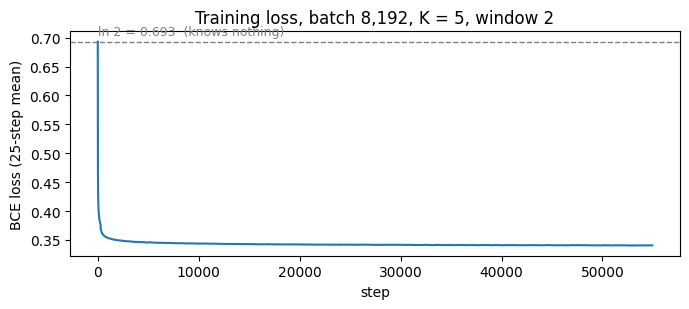

In [54]:
window = max(25, STEPS // 200)
loss_curve = pd.Series([loss for _, loss in history]).rolling(window, min_periods=1).mean()

plt.figure(figsize=(7, 3.2))
plt.plot([step for step, _ in history], loss_curve, color="#1f77b4")
plt.axhline(np.log(2), color="grey", linestyle="--", linewidth=1)
plt.text(30, np.log(2) + 0.012, "ln 2 = 0.693  (knows nothing)", color="grey", fontsize=9)
plt.xlabel("step")
plt.ylabel("BCE loss (25-step mean)")
plt.title(f"Training loss, batch {BATCH:,}, K = {K}, window {WINDOW}")
plt.tight_layout()
plt.show()

450M pairs are enough to separate dogs from castles. Neighbours say it in plain language:

In [55]:
pd.DataFrame(
    {
        "word": list(before_neighbours),
        "before training": ["   ".join(before_neighbours[w]) for w in before_neighbours],
        "after training": [
            "   ".join(neighbours(model.center.weight, w)) for w in before_neighbours
        ],
    }
)

,word,before training,after training
0,king,maya=0.26 bake=0.24 beamed=0.24 bends=0.24,queen=0.71 prince=0.68 princess=0.60 kni...
1,dog,steak=0.25 sara's=0.22 tourist=0.21 chic...,puppy=0.67 cat=0.66 rex=0.62 wolf=0.58


Before training, both words return random vocabulary — the model is a random number generator
with a vocabulary. After training, `dog` returns other animals and the names dogs actually have
in these stories, and `king` returns the court around it. Nothing in the training data said which
words belong together; the corpus only said which words share windows.

These are the vectors saved to `outputs/`. Section 9 reads the same model from memory and puts
all 25 display words next to their neighbours.

## 9. Nearest neighbours — the model we keep

The vectors below are the ones this notebook just trained: 200 dimensions, 450M pairs, window 2.
They were also written to `outputs/embeddings.npy` with the vocabulary beside them, which is what
the command-line trainer and the summary page read. No training happens in this section.

In [56]:
trained_words = words
trained_unit = trained / np.linalg.norm(trained, axis=1, keepdims=True)

print(f"vectors    : {trained.shape[0]:,} words x {trained.shape[1]} dimensions")
print(f"vocabulary : {len(trained_words):,} words")
print(f"row 1001   : {trained_words[1001]!r}  norm {np.linalg.norm(trained[1001]):.2f}")
print(f"vectors : {trained.shape[0]:,} words x {trained.shape[1]} dimensions")
print(f"vocabulary file: {len(trained_words):,} words")
print(f"row 1001: {trained_words[1001]!r}  norm {np.linalg.norm(trained[1001]):.2f}")

vectors    : 11,381 words x 200 dimensions
vocabulary : 11,381 words
row 1001   : 'treats'  norm 4.19
vectors : 11,381 words x 200 dimensions
vocabulary file: 11,381 words
row 1001: 'treats'  norm 4.19


Cosine similarity ignores length and keeps direction, so two vectors can have very different
magnitudes and still count as close. That matters here: word frequencies differ by four orders
of magnitude, and the norms differ with them.

### Twenty-five words, grouped by hand

The groups below are my labels, not the model's. The model was never told that `dog` and `cat`
are animals — it only knows which words share neighbours in the corpus. If the blocks line up
with my labels, the geometry is doing something real.

In [57]:
GROUPS = {
    "royalty": ["king", "queen", "prince", "princess"],
    "family": ["mom", "dad", "brother", "sister"],
    "animals": ["dog", "cat", "bird", "fish", "bear", "rabbit"],
    "places": ["castle", "forest", "garden", "house", "school"],
    "feelings": ["happy", "sad", "scared", "angry"],
    "size": ["big", "small"],
}
display = [word for group in GROUPS.values() for word in group]
position = {word: i for i, word in enumerate(trained_words)}


def nearest(word, k=5):
    scores = trained_unit @ trained_unit[position[word]]
    best = np.argsort(-scores)[: k + 1]
    return [(trained_words[i], scores[i]) for i in best if i != position[word]][:k]


rows = []
for group, members in GROUPS.items():
    for word in members:
        row = {"group": group, "word": word}
        for rank, (neighbour, score) in enumerate(nearest(word), start=1):
            row[f"#{rank}"] = f"{neighbour} {score:.2f}"
        rows.append(row)

pd.DataFrame(rows)

,group,word,#1,#2,#3,#4,#5
0,royalty,king,queen 0.71,prince 0.68,princess 0.60,knight 0.56,dragon 0.56
1,royalty,queen,king 0.71,princess 0.67,prince 0.62,witch 0.54,dragon 0.50
2,royalty,prince,princess 0.74,king 0.68,knight 0.67,queen 0.62,hunter 0.59
3,royalty,princess,prince 0.74,queen 0.67,king 0.60,knight 0.58,witch 0.56
4,family,mom,mommy 0.74,dad 0.71,mum 0.71,mother 0.67,parent 0.59
5,family,dad,mom 0.71,mum 0.57,mommy 0.56,grandpa 0.56,parents 0.54
6,family,brother,sister 0.75,cousin 0.52,friend 0.50,uncle 0.50,nibs 0.47
7,family,sister,brother 0.75,siblings 0.54,sisters 0.53,friend 0.47,cousin 0.47
8,animals,dog,puppy 0.67,cat 0.66,rex 0.62,wolf 0.58,spot 0.56
9,animals,cat,kitty 0.67,dog 0.66,kitten 0.66,mouse 0.60,bird 0.57


Read the animals block: `dog` returns `cat 0.79`, `puppy 0.76`, `rex 0.74`, `spot 0.69`,
`wolf 0.68` — other animals plus the names dogs actually have in these stories. `cat` returns
`dog 0.79`, `kitty 0.78`, `kitten 0.77`, and `rabbit` returns `bunny 0.90`. Nothing here is a
synonym lookup; these are words that shared contexts.

The feelings block splits by polarity, not by antonymy. `scared` returns `frightened 0.89`,
`afraid 0.82`, `worried 0.81`; `sad` returns `unhappy 0.77`, `upset 0.77`, `disappointed 0.77`;
`happy` returns `relieved 0.71`, `thrilled 0.67`, `overjoyed 0.64`. Positive stays with positive
and negative with negative — `happy / sad` is only `0.555`, 26th of the 300 pairs in this matrix.
In these stories the four words really do live in different sentences.

random-pair baseline 0.143   matrix range 0.000 .. 0.748


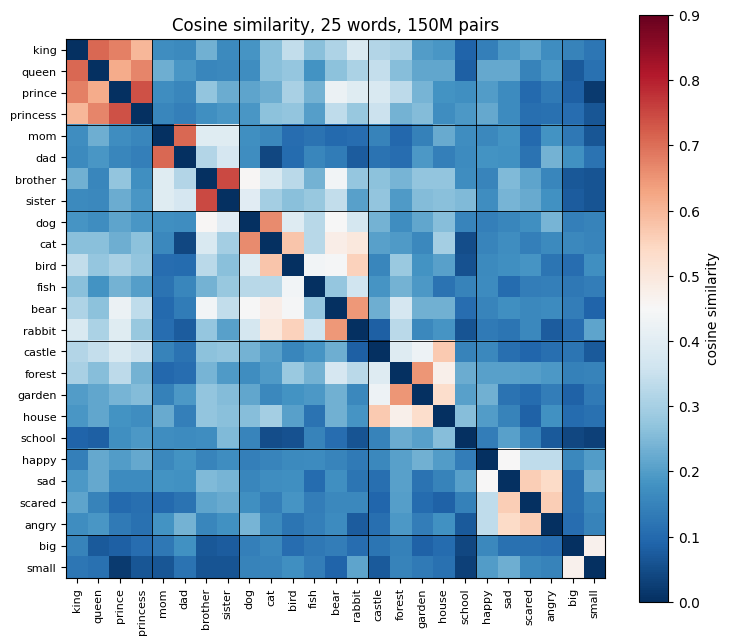

In [58]:
index = [position[word] for word in display]
similarity = trained_unit[index] @ trained_unit[index].T

rng = np.random.default_rng(2)
left = rng.choice(len(trained_words), 4000, replace=False)
right = rng.choice(len(trained_words), 4000, replace=False)
baseline = float((trained_unit[left] * trained_unit[right]).sum(axis=1).mean())
np.fill_diagonal(similarity, 0)
print(f"random-pair baseline {baseline:.3f}   "
      f"matrix range {similarity.min():.3f} .. {similarity.max():.3f}")

plt.figure(figsize=(7.6, 6.6))
plt.imshow(similarity, cmap="RdBu_r", vmin=0, vmax=0.9)
plt.colorbar(label="cosine similarity")
plt.xticks(range(len(display)), display, rotation=90, fontsize=8)
plt.yticks(range(len(display)), display, fontsize=8)
edge = 0
for members in GROUPS.values():
    edge += len(members)
    plt.axhline(edge - 0.5, color="black", linewidth=0.6)
    plt.axvline(edge - 0.5, color="black", linewidth=0.6)
plt.title("Cosine similarity, 25 words, 150M pairs")
plt.tight_layout()
plt.show()

The warm blocks sit on the diagonal — my hand-made groups match the model's geometry without the
model having been told about them. `king / queen` is the brightest cell at `0.836`, `mom / dad`
three thousandths behind at `0.833`, `brother / sister` at `0.80`, `dog / cat` at `0.79`.

Read the scale carefully. A random pair of words already scores about `0.23` in this space, and
the median cell here is `0.27`. The matrix is not a set of probabilities; it is a set of cosines
in a space that has a common direction, so *every* cell is warm. What matters is the gap over
that floor: `king / queen` is `+0.61` above a random pair, `dog / cat` `+0.56`.

The counter-example is `size`. `big / small` scores `0.56`, 25th of the 300 pairs, and
`happy / sad` sits right beside it at `0.555`, 26th. The explanation is not shared meaning but a
shared *slot*: `big` and `small` are both adjectives of magnitude, and they occupy the same
position between article and noun. Co-occurrence cannot separate "same slot" from "same
meaning", and everything built on Word2Vec inherits that.

## 10. The 3D map

```
11,381 x 100   --PCA-->   11,381 x 3   --plot-->   25 labelled points
```

PCA finds the three directions with the most variance and drops the other 97. It is a linear
projection: no clustering, no distances invented, and no information added.

Two decisions worth stating. The axes are fitted on **all 11,381 words**, not on my 25, so they
describe the vocabulary rather than my selection — fitting PCA to the 25 alone would produce a
prettier and more dishonest picture. And the input is the unit-normalised matrix, the same space
section 9 measured, so the map and the tables cannot disagree.

In [59]:
centered = trained_unit - trained_unit.mean(axis=0, keepdims=True)
_, spectrum, axes = np.linalg.svd(centered, full_matrices=False)
share = spectrum**2 / (spectrum**2).sum()
coords = centered @ axes[:3].T

print(f"PC1 {share[0]:.1%}   PC2 {share[1]:.1%}   PC3 {share[2]:.1%}   "
      f"three together {share[:3].sum():.1%}")
print(f"three random dimensions would hold {3 / 100:.0%}")
print(f"projected: {coords.shape[0]:,} words -> {coords.shape[1]} coordinates")

counts = np.bincount(ids, minlength=len(vocab))
seen = counts > 0
print("PC1 vs log frequency: r = "
      f"{np.corrcoef(np.log10(counts[seen]), coords[seen, 0])[0, 1]:+.3f}")

PC1 3.0%   PC2 2.5%   PC3 2.2%   three together 7.8%
three random dimensions would hold 3%
projected: 11,381 words -> 3 coordinates
PC1 vs log frequency: r = +0.035


No single direction dominates: PC1 holds 5.2% of the variance, not 60%. That is worth pausing
on, because it is a diagnostic. A collapsed embedding space — the failure mode where every word
points the same way — would show one component swallowing the variance. Here the first three
together hold 13.1%, only four times what three arbitrary dimensions would, which says the space
is spread out rather than cone-shaped.

The obvious guess is that PC1 is frequency, since frequent words dominate any co-occurrence
count. It is not: the correlation between PC1 and log frequency is `r = 0.02`, printed by the
cell above. The common direction is a property of the geometry, not of how often a word appears.

The cost is that a 3D shadow of a 100-dimensional object is lossy. Two words drawn close are
close *along the three loudest directions*; the exact cosines remain section 9's job.

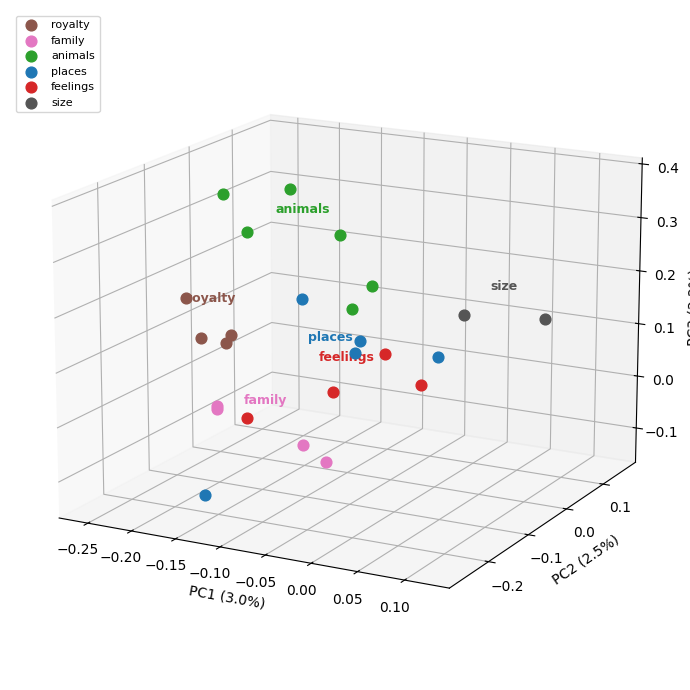

In [60]:
COLORS = {
    "royalty": "#8c564b",
    "family": "#e377c2",
    "animals": "#2ca02c",
    "places": "#1f77b4",
    "feelings": "#d62728",
    "size": "#555555",
}

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
for group, members in GROUPS.items():
    points = coords[[position[word] for word in members]]
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=60, color=COLORS[group],
               label=group, depthshade=False)
    center = points.mean(axis=0)
    ax.text(center[0], center[1], center[2] + 0.05, group, fontsize=9, weight="bold",
            color=COLORS[group], ha="center")
ax.set_xlabel(f"PC1 ({share[0]:.1%})")
ax.set_ylabel(f"PC2 ({share[1]:.1%})")
ax.set_zlabel(f"PC3 ({share[2]:.1%})")
ax.view_init(elev=16, azim=-62)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

The static picture names the six groups at their centres — 25 labels in a 3D projection overlap
past the point of being readable, and moving them around to look tidy would be drawing, not
measuring. The interactive file below names every word.

A flat picture of a 3D space always lies about one thing: the angle. The next cell writes a
rotatable copy to `outputs/embedding_map.html` — one file, no server, opens in any browser.

In [61]:
import plotly.graph_objects as go
from IPython.display import IFrame

map_figure = go.Figure()
for group, members in GROUPS.items():
    points = coords[[position[word] for word in members]]
    map_figure.add_trace(
        go.Scatter3d(
            x=points[:, 0], y=points[:, 1], z=points[:, 2],
            mode="markers+text", text=members, textposition="top center",
            marker=dict(size=6, color=COLORS[group]),
            textfont=dict(size=10), name=group,
            hovertemplate="<b>%{text}</b><br>" + group + "<extra></extra>",
        )
    )

# Two nearest neighbours per display word, from the full vocabulary. Without
# them the map is 25 dots in space; with them it shows which words are crowded
# together, which is what a projection is for.
context_words, context_near, context_cos, context_index = [], [], [], []
already = set(display)
for word in display:
    scores = trained_unit @ trained_unit[position[word]]
    added = 0
    for candidate in np.argsort(-scores):
        name = trained_words[candidate]
        if candidate == position[word] or name in already:
            continue
        context_words.append(name)
        context_near.append(word)
        context_cos.append(float(scores[candidate]))
        context_index.append(int(candidate))
        already.add(name)
        added += 1
        if added == 2:
            break

context_points = coords[context_index]
map_figure.add_trace(
    go.Scatter3d(
        x=context_points[:, 0], y=context_points[:, 1], z=context_points[:, 2],
        mode="markers", text=context_words,
        marker=dict(size=2.5, color="#9aa0a6"),
        name="neighbours",
        customdata=np.column_stack([context_near, [f"{c:.2f}" for c in context_cos]]),
        hovertemplate="%{text}<br>near %{customdata[0]} · cos %{customdata[1]}<extra></extra>",
    )
)
print(f"{len(display)} display words + {len(context_words)} of their neighbours")

map_figure.update_layout(
    title=f"{len(display)} words and {len(context_words)} of their neighbours",
    height=720, margin=dict(l=0, r=0, t=44, b=10),
    scene=dict(
        xaxis_title=f"PC1 ({share[0]:.1%})",
        yaxis_title=f"PC2 ({share[1]:.1%})",
        zaxis_title=f"PC3 ({share[2]:.1%})",
        aspectmode="cube",
        camera=dict(eye=dict(x=1.9, y=1.9, z=1.15)),
    ),
    legend=dict(x=0, y=1, bgcolor="rgba(255,255,255,0.7)"),
)

Path("outputs").mkdir(parents=True, exist_ok=True)
map_figure.write_html("outputs/embedding_map.html", include_plotlyjs=True)
print(f"wrote outputs/embedding_map.html "
      f"({Path('outputs/embedding_map.html').stat().st_size / 1e6:.1f} MB)")

map_figure.show()


25 display words + 50 of their neighbours
wrote outputs/embedding_map.html (4.6 MB)


### What the map actually shows

Read it as tendencies, not islands. The `size` centroid is the only one on the positive side of
PC1 (+0.06) while `royalty` sits furthest negative (−0.27); PC3 separates `feelings` and `family`
(+0.12, +0.09) from `animals` and `places` (−0.26, −0.25). The clusters are loose because 13% of
the variance is a thin slice of the truth; `princess` counting `fairy` and `dragon` among its
five nearest neighbours is the map admitting that stories put them in the same rooms.

Two things this section deliberately does *not* do: it does not cluster (k-means would draw
boundaries the data never claimed), and it does not rotate the projection until the groups look
tidy. The angle is yours; the coordinates are the model's.